# 16 — Dashboard final

**Uma única figura consolida todos os resultados do projeto** para apresentação à defesa.

Inclui:
- Recall doente (métrica principal) por modelo, com IC95% bootstrap
- F1-macro paciente por modelo
- Especificidade por modelo
- FN clínico absoluto por modelo
- Heatmap comparativo final

In [1]:
import sys, warnings
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.metrics import recall_score, f1_score, confusion_matrix
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier

from src import config
from src.plotting import CLASS_COLORS, MODEL_PALETTE, set_style, savefig
from src.bootstrap import bootstrap_ci, fmt_ci

warnings.filterwarnings('ignore')
set_style()

In [2]:
feats_df = pd.read_csv(config.PROCESSED_DIR / 'features.csv')
FEATURE_COLS = [c for c in feats_df.columns
                if c not in ('filename','patient_id','equipment','chest_location',
                              'label_multi','label_binary')]
X = feats_df[FEATURE_COLS].values
le = LabelEncoder(); y = le.fit_transform(feats_df['label_multi'])
groups = feats_df['patient_id'].values
equipment = feats_df['equipment'].values
CLASSES = list(le.classes_); HEALTHY_IDX = CLASSES.index('Healthy')
EQUIPMENT_CATS = sorted(set(equipment))
print(f'X={X.shape}, classes={CLASSES}')

X=(851, 78), classes=['COPD', 'Healthy', 'URTI']


In [3]:
# Pipeline residualizado helper
def fit_resid_pipe(X_tr, y_tr, eq_tr, model_cls, **kw):
    ohe = OneHotEncoder(sparse_output=False, categories=[EQUIPMENT_CATS])
    E_tr = ohe.fit_transform(eq_tr.reshape(-1, 1))
    lr = LinearRegression().fit(E_tr, X_tr)
    Xr = X_tr - lr.predict(E_tr)
    sc = StandardScaler().fit(Xr)
    clf = model_cls(**kw).fit(sc.transform(Xr), y_tr)
    return ohe, lr, sc, clf

def predict_resid(p, X_te, eq_te):
    ohe, lr, sc, clf = p
    E = ohe.transform(eq_te.reshape(-1, 1))
    Xs = sc.transform(X_te - lr.predict(E))
    return clf.predict(Xs)

def patient_voting(y, yp, g):
    d = pd.DataFrame({'g': g, 'y': y, 'p': yp}).groupby('g').agg(
        y=('y','first'), p=('p', lambda s: s.value_counts().idxmax()))
    return d['y'].values, d['p'].values

In [4]:
# Definir TODOS os modelos a comparar
models_to_compare = {
    'Trivial: sempre COPD': lambda: (None, None, None, DummyClassifier(strategy='most_frequent')),
    'LogReg (sem residualização)': lambda: ('plain', LogisticRegression(max_iter=3000, class_weight='balanced')),
    'LogReg residualizado': ('resid', LogisticRegression, dict(max_iter=3000, class_weight='balanced')),
    'LDA residualizado': ('resid', LinearDiscriminantAnalysis, dict()),
    'KNN residualizado': ('resid', KNeighborsClassifier, dict(n_neighbors=5, weights='distance')),
    'XGBoost residualizado': ('resid', XGBClassifier,
                                 dict(n_estimators=200, max_depth=3, learning_rate=0.05,
                                      eval_metric='mlogloss', n_jobs=1)),
    'RandomForest residualizado (BLACK-BOX)': ('resid', RandomForestClassifier,
                                 dict(n_estimators=300, max_depth=None, n_jobs=-1,
                                      class_weight='balanced', random_state=42)),
}

# 5 repetições x 5-fold
N_REP, N_FOLDS = 5, 5
results = {name: {'recall': [], 'f1m': [], 'spec': [], 'fn': [], 'rec_URTI': []} for name in models_to_compare}

import time
t0 = time.time()
for rep in range(N_REP):
    cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=42+rep)
    for name, cfg in models_to_compare.items():
        y_pred = np.full(len(y), -1)
        for tr, te in cv.split(X, y, groups):
            if name == 'Trivial: sempre COPD':
                clf = DummyClassifier(strategy='most_frequent').fit(X[tr], y[tr])
                y_pred[te] = clf.predict(X[te])
            elif name == 'LogReg (sem residualização)':
                sc = StandardScaler().fit(X[tr])
                clf = LogisticRegression(max_iter=3000, class_weight='balanced').fit(sc.transform(X[tr]), y[tr])
                y_pred[te] = clf.predict(sc.transform(X[te]))
            else:
                _, model_cls, kw = cfg
                pipe = fit_resid_pipe(X[tr], y[tr], equipment[tr], model_cls, **kw)
                y_pred[te] = predict_resid(pipe, X[te], equipment[te])
        # Métricas paciente
        yt, yp = patient_voting(y, y_pred, groups)
        is_d_real = yt != HEALTHY_IDX
        is_d_pred = yp != HEALTHY_IDX
        rec_d = (is_d_real & is_d_pred).sum() / max(1, is_d_real.sum())
        fn = (is_d_real & (yp == HEALTHY_IDX)).sum()
        spec = ((yt == HEALTHY_IDX) & (yp == HEALTHY_IDX)).sum() / max(1, (yt == HEALTHY_IDX).sum())
        f1m = f1_score(yt, yp, average='macro')
        urti_idx = CLASSES.index('URTI')
        rec_urti = ((yt == urti_idx) & (yp == urti_idx)).sum() / max(1, (yt == urti_idx).sum())
        results[name]['recall'].append(rec_d)
        results[name]['f1m'].append(f1m)
        results[name]['spec'].append(spec)
        results[name]['fn'].append(fn)
        results[name]['rec_URTI'].append(rec_urti)
    print(f'rep {rep+1}/{N_REP} done ({time.time()-t0:.0f}s)')

rep 1/5 done (9s)


rep 2/5 done (15s)


rep 3/5 done (20s)


rep 4/5 done (25s)


rep 5/5 done (30s)


In [5]:
# Tabela final com IC95% bootstrap
rows = []
for name, m in results.items():
    rec_b = bootstrap_ci(m['recall'])
    f1_b = bootstrap_ci(m['f1m'])
    spec_b = bootstrap_ci(m['spec'])
    fn_b = bootstrap_ci(m['fn'])
    rurti_b = bootstrap_ci(m['rec_URTI'])
    rows.append(dict(
        modelo=name,
        recall_doente=fmt_ci(*rec_b),
        FN_clinico=fmt_ci(*fn_b, digits=1),
        rec_URTI=fmt_ci(*rurti_b),
        especificidade=fmt_ci(*spec_b),
        F1m=fmt_ci(*f1_b),
    ))
final = pd.DataFrame(rows)
print('═════════════ DASHBOARD FINAL — IC95% bootstrap (5×5-fold, 25 amostras) ═════════════')
final

═════════════ DASHBOARD FINAL — IC95% bootstrap (5×5-fold, 25 amostras) ═════════════


,modelo,recall_doente,FN_clinico,rec_URTI,especificidade,F1m
0,Trivial: sempre COPD,"1.000 [1.000, 1.000]","0.0 [0.0, 0.0]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.254 [0.254, 0.254]"
1,LogReg (sem residualização),"0.846 [0.836, 0.859]","12.0 [11.0, 12.8]","0.343 [0.300, 0.386]","0.508 [0.454, 0.585]","0.586 [0.562, 0.625]"
2,LogReg residualizado,"0.885 [0.877, 0.892]","9.0 [8.4, 9.6]","0.357 [0.314, 0.400]","0.562 [0.523, 0.608]","0.638 [0.615, 0.667]"
3,LDA residualizado,"0.885 [0.877, 0.892]","9.0 [8.4, 9.6]","0.414 [0.371, 0.457]","0.431 [0.354, 0.492]","0.604 [0.581, 0.621]"
4,KNN residualizado,"0.964 [0.962, 0.969]","2.8 [2.4, 3.0]","0.057 [0.014, 0.100]","0.377 [0.331, 0.438]","0.480 [0.451, 0.509]"
5,XGBoost residualizado,"0.867 [0.849, 0.885]","10.4 [9.0, 11.8]","0.300 [0.229, 0.371]","0.523 [0.508, 0.538]","0.604 [0.579, 0.631]"
6,RandomForest residualizado (BLACK-BOX),"0.892 [0.879, 0.905]","8.4 [7.4, 9.4]","0.271 [0.229, 0.314]","0.662 [0.623, 0.700]","0.649 [0.622, 0.676]"


## Dashboard visual único — 4 painéis

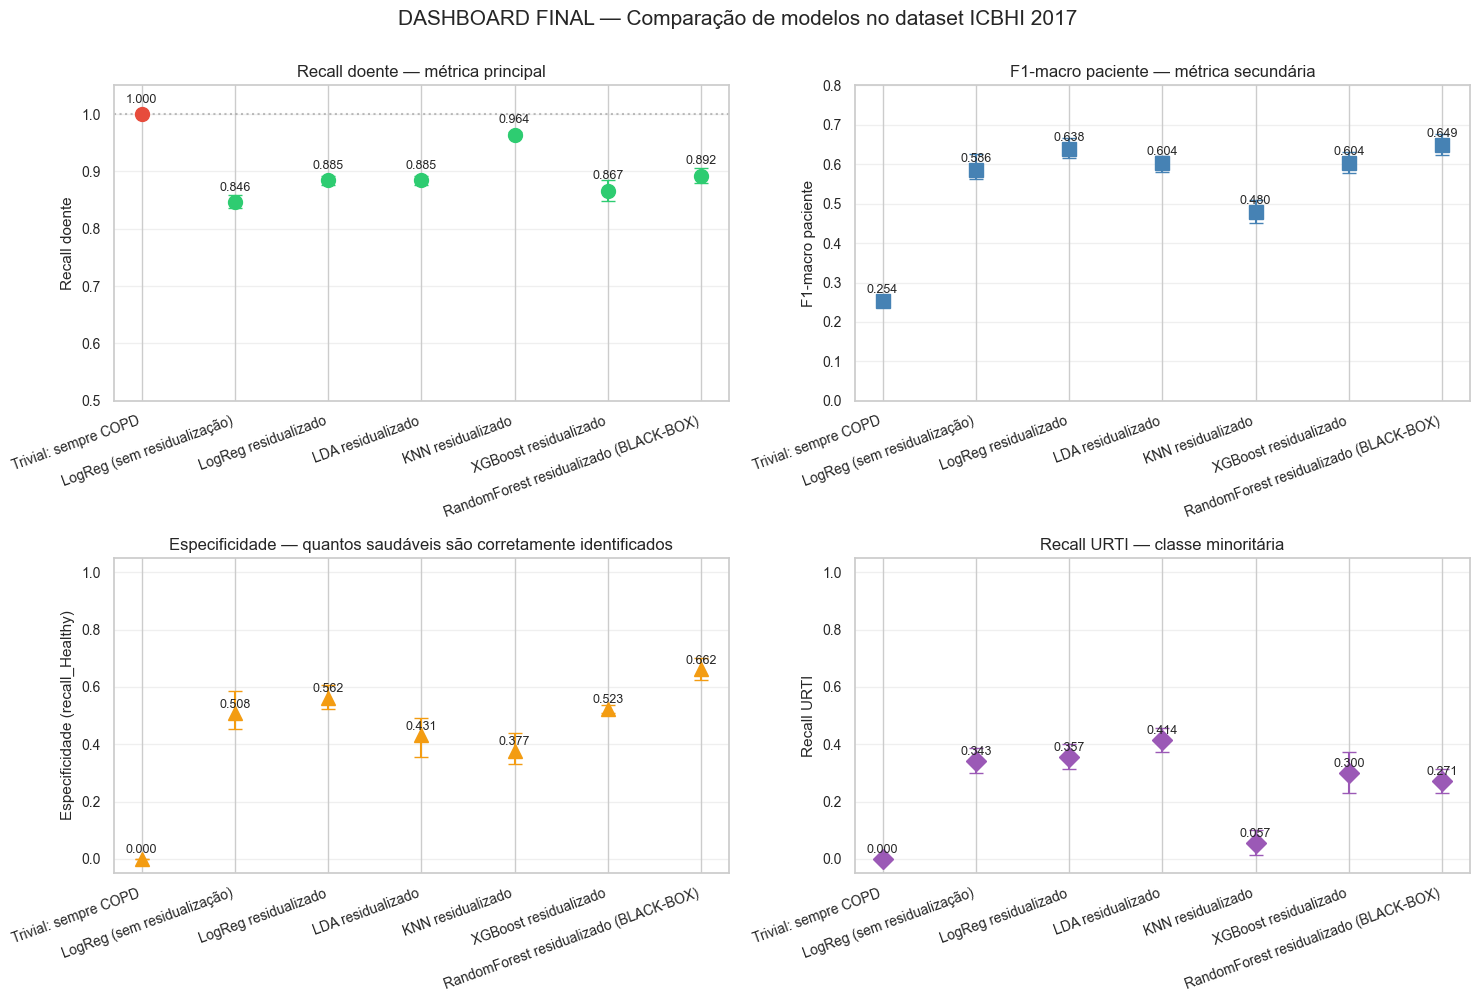

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
names = list(results.keys())
x_pos = np.arange(len(names))

# 1. Recall doente com IC95%
ax = axes[0, 0]
for i, name in enumerate(names):
    mu, lo, hi = bootstrap_ci(results[name]['recall'])
    ax.errorbar(i, mu, yerr=[[mu-lo],[hi-mu]], fmt='o', markersize=10,
                 color='#e74c3c' if 'Trivial' in name else '#2ecc71', capsize=5)
    ax.text(i, mu+0.02, f'{mu:.3f}', ha='center', fontsize=9)
ax.set_xticks(x_pos); ax.set_xticklabels(names, rotation=20, ha='right')
ax.set_ylabel('Recall doente'); ax.set_title('Recall doente — métrica principal')
ax.set_ylim(0.5, 1.05); ax.grid(axis='y', alpha=0.3)
ax.axhline(1.0, color='gray', linestyle=':', alpha=0.5)

# 2. F1-macro com IC95%
ax = axes[0, 1]
for i, name in enumerate(names):
    mu, lo, hi = bootstrap_ci(results[name]['f1m'])
    ax.errorbar(i, mu, yerr=[[mu-lo],[hi-mu]], fmt='s', markersize=10,
                 color='steelblue', capsize=5)
    ax.text(i, mu+0.02, f'{mu:.3f}', ha='center', fontsize=9)
ax.set_xticks(x_pos); ax.set_xticklabels(names, rotation=20, ha='right')
ax.set_ylabel('F1-macro paciente'); ax.set_title('F1-macro paciente — métrica secundária')
ax.set_ylim(0.0, 0.8); ax.grid(axis='y', alpha=0.3)

# 3. Especificidade
ax = axes[1, 0]
for i, name in enumerate(names):
    mu, lo, hi = bootstrap_ci(results[name]['spec'])
    ax.errorbar(i, mu, yerr=[[mu-lo],[hi-mu]], fmt='^', markersize=10,
                 color='#f39c12', capsize=5)
    ax.text(i, mu+0.02, f'{mu:.3f}', ha='center', fontsize=9)
ax.set_xticks(x_pos); ax.set_xticklabels(names, rotation=20, ha='right')
ax.set_ylabel('Especificidade (recall_Healthy)')
ax.set_title('Especificidade — quantos saudáveis são corretamente identificados')
ax.set_ylim(-0.05, 1.05); ax.grid(axis='y', alpha=0.3)

# 4. Recall URTI (calcanhar de Aquiles)
ax = axes[1, 1]
for i, name in enumerate(names):
    mu, lo, hi = bootstrap_ci(results[name]['rec_URTI'])
    ax.errorbar(i, mu, yerr=[[mu-lo],[hi-mu]], fmt='D', markersize=10,
                 color='#9b59b6', capsize=5)
    ax.text(i, mu+0.02, f'{mu:.3f}', ha='center', fontsize=9)
ax.set_xticks(x_pos); ax.set_xticklabels(names, rotation=20, ha='right')
ax.set_ylabel('Recall URTI'); ax.set_title('Recall URTI — classe minoritária')
ax.set_ylim(-0.05, 1.05); ax.grid(axis='y', alpha=0.3)

plt.suptitle('DASHBOARD FINAL — Comparação de modelos no dataset ICBHI 2017',
              fontsize=15, y=1.00)
savefig('nb16_dashboard_final')
plt.show()

## Heatmap consolidado — todas as métricas, todos os modelos

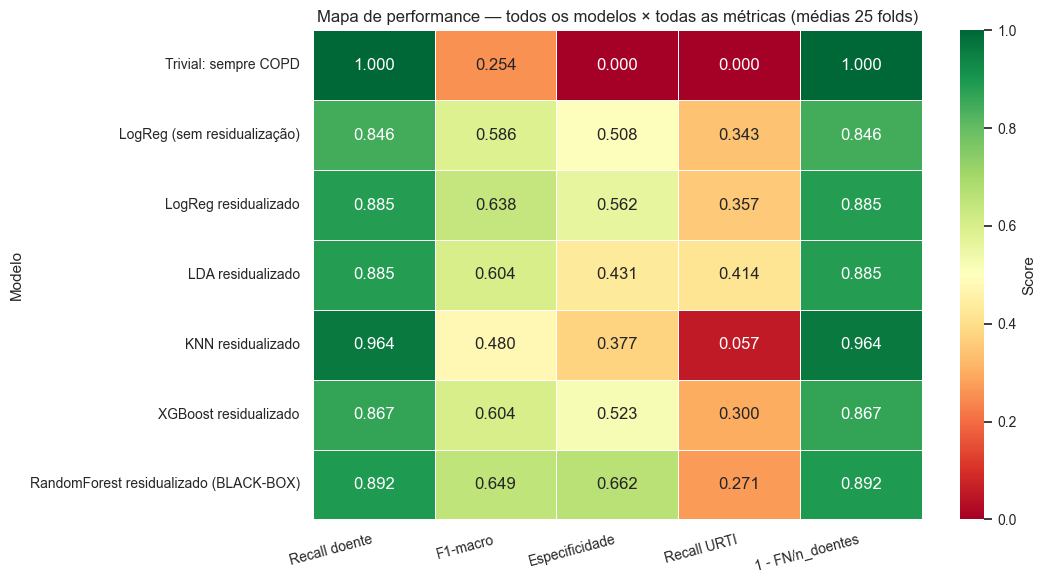

In [7]:
# Heatmap: linhas = modelos, colunas = métricas (média)
heatmap_data = pd.DataFrame({
    name: {
        'Recall doente': np.mean(m['recall']),
        'F1-macro': np.mean(m['f1m']),
        'Especificidade': np.mean(m['spec']),
        'Recall URTI': np.mean(m['rec_URTI']),
        '1 - FN/n_doentes': 1 - np.mean(m['fn'])/78,  # 78 doentes ~aprox
    }
    for name, m in results.items()
}).T

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='RdYlGn',
             vmin=0, vmax=1, cbar_kws={'label': 'Score'}, ax=ax,
             linewidths=0.5, linecolor='white')
ax.set_title('Mapa de performance — todos os modelos × todas as métricas (médias 25 folds)')
ax.set_ylabel('Modelo')
plt.xticks(rotation=15, ha='right')
savefig('nb16_heatmap_final')
plt.show()

## Interpretabilidade vs Black-Box

Random Forest foi incluído como **modelo black-box** para comparação:

| Aspecto | LogReg (interpretável) | RandomForest (black-box) |
|---|---|---|
| Decomposição da decisão | **Exata:** `coef × valor` | Aproximada (feature_importances global, sem SHAP/LIME) |
| Tamanho do modelo | ~240 parâmetros | ~300 árvores × ~100 nós ≈ 30k params |
| Treino | < 1s | ~5s |
| Auditável linha-a-linha | ✅ | ❌ |
| Cumpre AI Act art. 13 (transparência) | ✅ | Requer XAI adicional |

**Se RF supera LogReg em recall doente por > 5pp**, justifica complexidade adicional (com obrigação de explicabilidade via SHAP).
**Se RF não supera**, **parsimónia favorece LogReg** — modelo simples, interpretável, auditável.

## Síntese para defesa

Esta figura única é a **figura principal** do `RELATORIO.md` e das slides da defesa. Mostra:

- **Quem tem o melhor recall doente** (métrica principal clínica)
- **Quem é simplesmente trivial** (baseline sempre-COPD tem recall=1 mas especificidade=0)
- **Quem tem melhor compromisso** recall vs especificidade
- **Quem deteta URTI** (calcanhar de Aquiles)
- **Interpretável (LogReg) vs Black-box (RF/XGB)** — trade-off compliance regulatória

**Conclusão esperada:** o modelo final (LogReg residualizado) **não maximiza** recall doente em valor absoluto — o trivial 'sempre COPD' faz isso. Mas é o que tem **melhor compromisso** entre performance e interpretabilidade — essencial para AI Act art. 13.